In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils
# noinspection PyUnresolvedReferences
from utils import artificializer

# noinspection PyUnresolvedReferences
from models import bom_sep as bom
# noinspection PyUnresolvedReferences
from models import hgm_sep as hgm

# noinspection PyUnresolvedReferences
from models import bom as bom_gen
# noinspection PyUnresolvedReferences
from models import hgm as hgm_gen

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)
importlib.reload(bom_gen)
importlib.reload(hgm_gen)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/models/hgm.py'>

In [3]:
default_hyperparameters = {
	'max_epochs': 3000,
	'max_patience': 3000 / 3,
	'learning_rate': 1E-0,
	'w1_reg_lambda': 0.0,
	'w2_reg_lambda': 0.0,
}

# Functions

In [4]:
class Lambdas(NamedTuple):
	reg_lambdas: tuple[float, float]

In [5]:
def train_model(model, splits, N_res, B_ll, N_man, hyperparams=None):
	#region hyperparamters ===============================================================
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	global default_hyperparameters
	hyperparameters = default_hyperparameters.copy()
	if hyperparams is not None:
		for key in hyperparams:
			hyperparameters[key] = hyperparams[key]

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	lambdas = Lambdas(
		reg_lambdas=(hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda'])
	)
	#endregion ===========================================================================

	n_neurons = N_res.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop ==============================
	params_per_split = list()
	(losses_train_per_split,
	 mpe_losses_train_per_split) = list(), list()
	(losses_per_split,
	 mpe_losses_per_split) = list(), list()
	for s_id, (train, eval) in enumerate(splits):
		#region splitting and initializing (this also moves the data to the GPU) ==========================
		N_res_train, N_res_eval = jnp.array(N_res[train]), jnp.array(N_res[eval])
		B_ll_train, B_ll_eval = jnp.array(B_ll[train]), jnp.array(B_ll[eval])
		if model.get_type(): N_man_train, N_man_eval = jnp.array(N_man[train]), jnp.array(N_man[eval])

		params = model.init_params(seeds,
								   (n_behaviors_ll, n_neurons),
								   * ((N_man.shape[1], n_neurons),) if model.get_type() else (),
								  )
		# params = {
		# 	'model': artificializer.generate_params((0.1, -0.25), model, seeds, (n_behaviors_ll, n_neurons), (N_man.shape[1], n_neurons) if model.get_type() else None, scaling=0.5)
		# }

		optimizer = optax.adam(learning_rate=optax.cosine_decay_schedule(init_value=learning_rate, decay_steps=max_epochs, alpha=1E-4))
		# optimizer = optax.adam(learning_rate=learning_rate)
		opt_state = optimizer.init(params)
		#endregion ========================================================================================

		losses_train, mpe_losses_train = [], []
		losses, mpe_losses = [], []

		best_params = params
		(best_loss_train,
		 best_mpe_loss_train) = sys.float_info.max, sys.float_info.max
		(best_loss,
		 best_mpe_loss) = sys.float_info.max, sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):

			if model.get_type():
				(loss,
				 mpe_loss) = tuple(l.item() for l in model.loss_fn(params, N_res_eval, B_ll_eval, N_man_eval, lambdas))

				(opt_state, params, loss_types_train) = model.update(optimizer.update, opt_state, params, N_res_train, B_ll_train, N_man_train, lambdas)
			else:
				(loss,
				 mpe_loss) = tuple(l.item() for l in model.loss_fn(params, N_res_eval, B_ll_eval, lambdas))

				(opt_state, params, loss_types_train) = model.update(optimizer.update, opt_state, params, N_res_train, B_ll_train, lambdas)

			(loss_train,
			 mpe_loss_train) = tuple(l.item() for l in loss_types_train)

			#region early stopping ===========================================================================
			if epoch >= max_patience:  # give it an initial time
				if loss < best_loss:
					patience = 0

					best_params = params
					(best_loss_train,
					 best_mpe_loss_train) = loss_train, mpe_loss_train
					(best_loss,
					 best_mpe_loss) = loss, mpe_loss
				else:
					patience += 1
					if patience > max_patience:
						params = best_params

						losses_train = losses_train + [best_loss_train for _ in range(max_epochs - epoch)]
						mpe_losses_train = mpe_losses_train + [best_mpe_loss_train for _ in range(max_epochs - epoch)]

						losses = losses + [best_loss for _ in range(max_epochs - epoch)]
						mpe_losses = mpe_losses + [best_mpe_loss for _ in range(max_epochs - epoch)]

						print(f'Stopped after {epoch} epochs: ', end='')
						break

						# lr_step += 1
						# optimizer = optax.adam(learning_rate / (10 ** lr_step))
						# patience = 0
						# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')
			#endregion =======================================================================================

			losses_train.append(loss_train)
			mpe_losses_train.append(mpe_loss_train)

			losses.append(loss)
			mpe_losses.append(mpe_loss)

		params_per_split.append(params)

		losses_train_per_split.append(losses_train)
		mpe_losses_train_per_split.append(mpe_losses_train)

		losses_per_split.append(losses)
		mpe_losses_per_split.append(mpe_losses)

		print(f'Split {s_id} completed. ', end='')

	# ============================================

	# return (this also moves the data to the CPU)
	return (params_per_split,
			np.array(losses_train_per_split), np.array(mpe_losses_train_per_split),
			np.array(losses_per_split), np.array(mpe_losses_per_split))

In [6]:
def train_models(model, filenames, traces_residual, eigenworms, modes, discrete_states, hyperparams=None, save_name=None):
	models_params = list()
	models_losses, models_mpe_losses = list(), list()
	models_losses_train, models_mpe_losses_train = list(), list()

	for i in range(len(filenames)):
		print(f'\n{i+1}/{len(filenames)}: {filenames[i]}... ', end='')

		splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_residual[i].shape[0]), discrete_states[i][['REV']].values))

		(params_per_split,
		 losses_train_per_split, mpe_losses_train_per_split,
		 losses_per_split, mpe_losses_per_split
		 ) = train_model(model, splits,
						 traces_residual[i].values,
						 eigenworms[i].values,
						 modes[i].values,
						 hyperparams)

		models_params.append(params_per_split)

		models_losses_train.append(losses_train_per_split)
		models_mpe_losses_train.append(mpe_losses_train_per_split)

		models_losses.append(losses_per_split)
		models_mpe_losses.append(mpe_losses_per_split)

	if save_name is not None:
		train_utils.save_params(filenames, models_params, save_name)
		train_utils.save_losses(filenames, [
			np.array([models_losses_train[i], models_mpe_losses_train[i],
					  models_losses[i], models_mpe_losses[i]]) for i in range(len(filenames))
		], save_name)

	return (models_params,
			models_losses_train, models_mpe_losses_train,
			models_losses, models_mpe_losses)

# read & prep

In [7]:
dims = 2

bom_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w1_reg_lambda': 1E-2,
}
hgm_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	# 'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
	'w1_reg_lambda': 3E-3,
	'w2_reg_lambda': 1E-6,
}


selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']


gcamp = False
# read_ids_gcamp = list(range(0, 33+1))
# read_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
read_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	read_ids_gfp = list(range(0, 7+1))
	# read_ids_gfp = [2, 4, 6]
	# read_ids_gfp = [2]
	plot_id_gfp = 2


artificial = False
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)

In [8]:
# read

path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# remove unused discrete state labels
discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])

modes_gcamp, _, traces_reconstructed_gcamp, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_gcamp, discrete_states_gcamp, n_cv=dims, n_pc=0)
traces_residual_gcamp = [pd.DataFrame(data=trace_gcamp.values - trace_gcamp_reconstructed.values, columns=trace_gcamp.columns) for trace_gcamp, trace_gcamp_reconstructed in zip(traces_gcamp, traces_reconstructed_gcamp)]


if gfp:
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path_gfp, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# remove unused discrete state labels
	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])

	modes_gfp, _, traces_reconstructed_gfp, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_gfp, discrete_states_gfp, n_cv=dims, n_pc=0)
	traces_residual_gfp = [pd.DataFrame(data=trace_gfp.values - trace_gfp_reconstructed.values, columns=trace_gfp.columns) for trace_gfp, trace_gfp_reconstructed in zip(traces_gfp, traces_reconstructed_gfp)]


# generate
if artificial:
	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm_gen,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_gcamp[i],
														 discrete_states_gcamp[i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gcamp[i])

		discrete_states_art.append(discrete_states_gcamp[i].copy())
		eigenworms_art.append(eigenworms_gcamp[i].copy())

In [9]:
selection_n_gcamp = [label for label in selection_n if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]
if gfp:
	selection_n_gfp = [label for label in selection_n if label in traces_gfp[file_ids_gfp.index(plot_id_gfp)].columns]

# ARTIFICIAL

In [10]:
if artificial:
	plot_utils.plot_traces(f'[{filenames_art[file_ids_art.index(plot_id_gcamp)]}] residuals traces artificial',
						   discrete_states_art[file_ids_art.index(plot_id_gcamp)][['REV']],
						   traces_residual_art[file_ids_art.index(plot_id_gcamp)][selection_n_gcamp],
						   plots_per_row=2, ylimits=None)

In [11]:
if artificial:
	plot_utils.plot_traces(f'[{filenames_art[file_ids_gcamp.index(plot_id_gcamp)]}] traces artificial',
						   discrete_states_art[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
						   traces_art[file_ids_gcamp.index(plot_id_gcamp)][selection_n_gcamp],
						   plots_per_row=2, ylimits=None)

### BOM

In [12]:
if artificial:
	(boms_params_art,
	 boms_losses_train_art, boms_mpe_losses_train_art,
	 boms_losses_art, boms_mpe_losses_art
	 ) = train_models(bom,
					  filenames_art,
					  traces_residual_art,
					  eigenworms_art,
					  modes_art,
					  discrete_states_art,
					  hyperparams=bom_reg_lamdas,
					  save_name=f'sep_bom_art_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None

### HGM

In [13]:
if artificial:
	(hgms_params_art,
	 hgms_losses_train_art, hgms_mpe_losses_train_art,
	 hgms_losses_art, hgms_mpe_losses_art,
	 ) = train_models(hgm,
					  filenames_art,
					  traces_residual_art,
					  eigenworms_art,
					  modes_art,
					  discrete_states_art,
					  hyperparams=hgm_reg_lamdas,
					  save_name=f'sep_hgm_art_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None

## losses

In [14]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: train',
								  filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  ylimits=None)

In [15]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: test',
								  filenames_art,
								  hgms_losses_art, boms_losses_art,
								  ylimits=None)

In [16]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe train',
								  filenames_art,
								  hgms_mpe_losses_train_art, boms_mpe_losses_train_art,
								  ylimits=None)

In [17]:
if artificial:
	plot_utils.plot_losses_splits('artificial hgm vs bom: mpe test',
								  filenames_art,
								  hgms_mpe_losses_art, boms_mpe_losses_art,
								  ylimits=None)

# GCAMP

In [18]:
if gcamp:
	plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]}] gcamp traces',
						   discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
						   traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_gcamp],
						   plots_per_row=2, ylimits=None)

In [19]:
if gcamp:
	plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]}] gcamp traces',
						   discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
						   traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_gcamp],
						   plots_per_row=2, ylimits=None)

In [20]:
if gcamp:
	plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]}] residuals traces gcamp',
						   discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']],
						   traces_residual_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_gcamp],
						   plots_per_row=2, ylimits=None)

### BOM

In [21]:
if gcamp:
	(boms_params_gcamp,
	 boms_losses_train_gcamp, boms_mpe_losses_train_gcamp,
	 boms_losses_gcamp, boms_mpe_losses_gcamp,
	 ) = train_models(bom,
					  filenames_gcamp,
					  traces_residual_gcamp,
					  eigenworms_gcamp,
					  modes_gcamp,
					  discrete_states_gcamp,
					  hyperparams=bom_reg_lamdas,
					  save_name=f'sep_bom_gcamp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None


### HGM

In [22]:
if gcamp:
	(hgms_params_gcamp,
	 hgms_losses_train_gcamp, hgms_mpe_losses_train_gcamp,
	 hgms_losses_gcamp, hgms_mpe_losses_gcamp,
	 ) = train_models(hgm,
					  filenames_gcamp,
					  traces_residual_gcamp,
					  eigenworms_gcamp,
					  modes_gcamp,
					  discrete_states_gcamp,
					  hyperparams=hgm_reg_lamdas,
					  save_name=f'sep_hgm_gcamp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None

### losses

In [23]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
								  filenames_gcamp,
								  hgms_losses_train_gcamp, boms_losses_train_gcamp,
								  ylimits=None)

In [24]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
								  filenames_gcamp,
								  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
								  ylimits=None)

In [25]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
								  filenames_gcamp,
								  hgms_losses_gcamp, boms_losses_gcamp,
								  ylimits=None)

In [26]:
if gcamp:
	plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
								  filenames_gcamp,
								  hgms_mpe_losses_gcamp, boms_mpe_losses_gcamp,
								  ylimits=None)

# GFP

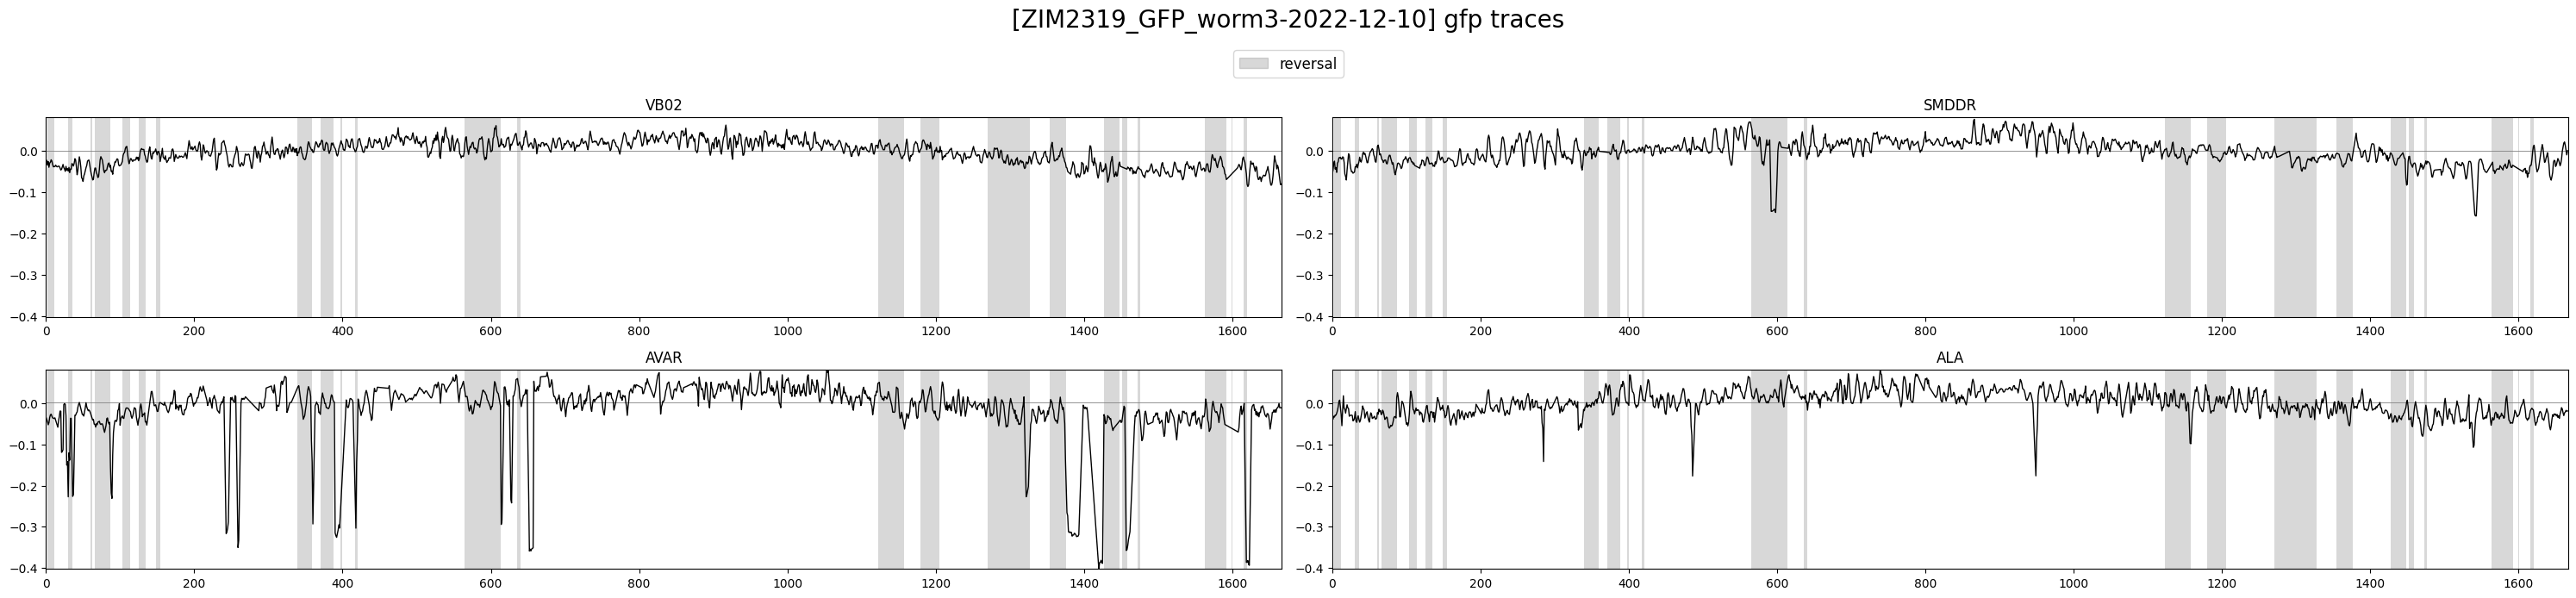

In [27]:
if gfp:
	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id_gfp)]}] gfp traces',
						   discrete_states_gfp[file_ids_gfp.index(plot_id_gfp)][['REV']],
						   traces_gfp[file_ids_gfp.index(plot_id_gfp)][selection_n_gfp],
						   plots_per_row=2, ylimits=None)

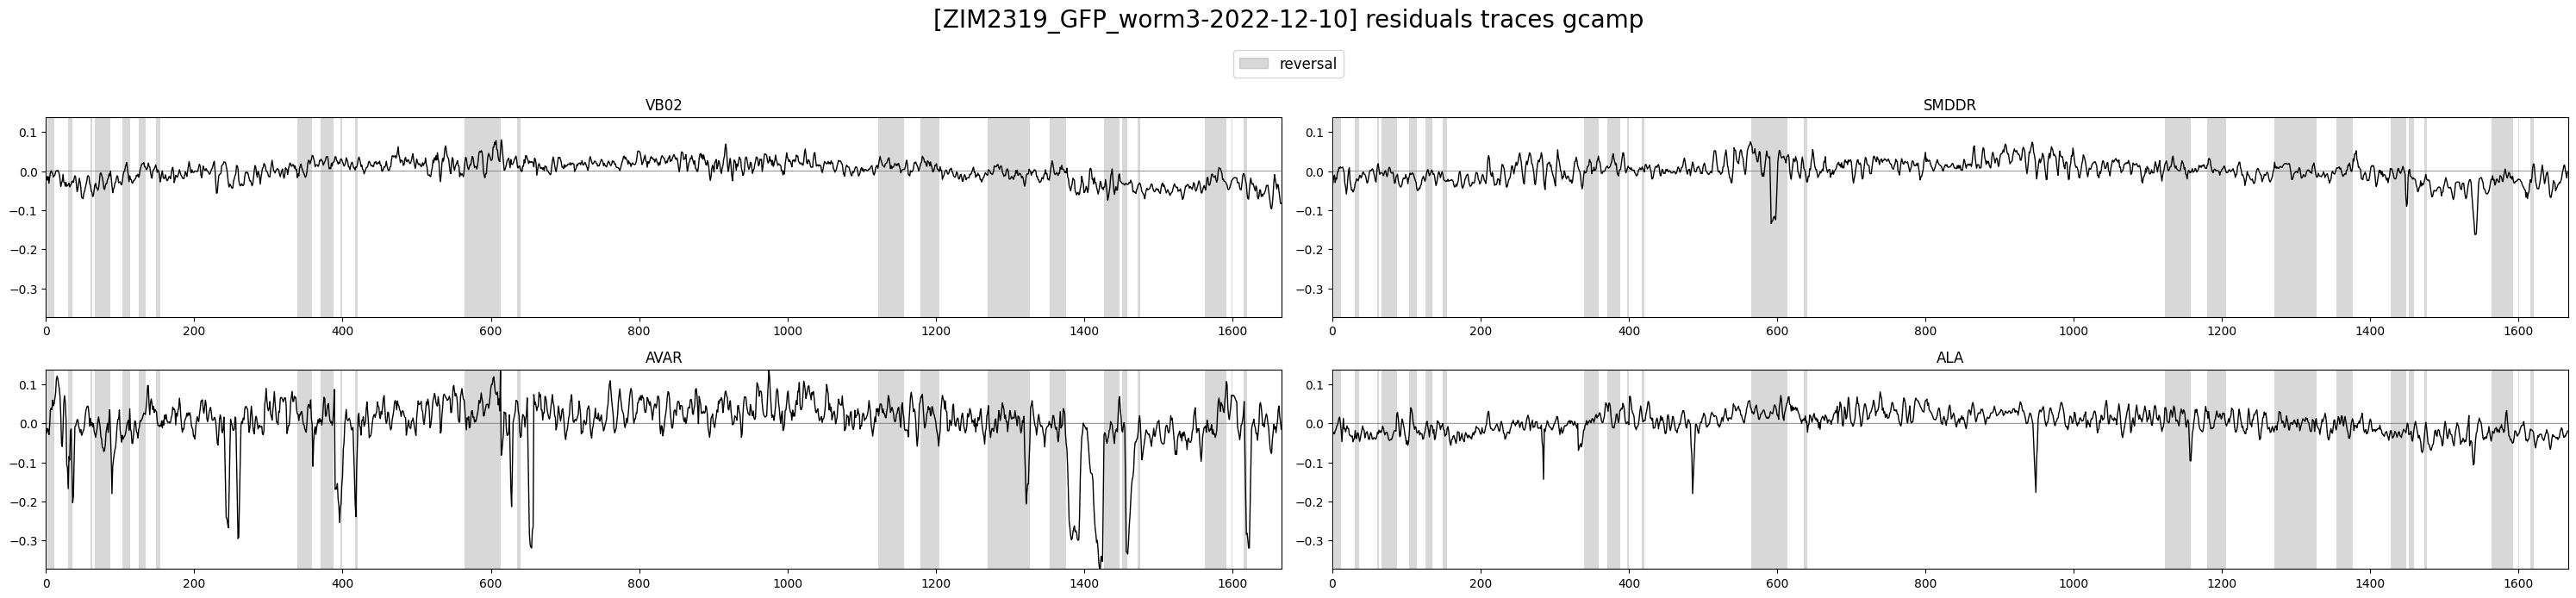

In [28]:
if gfp:
	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id_gfp)]}] residuals traces gcamp',
						   discrete_states_gfp[file_ids_gfp.index(plot_id_gfp)][['REV']],
						   traces_residual_gfp[file_ids_gfp.index(plot_id_gfp)][selection_n_gfp],
						   plots_per_row=2, ylimits=None)

### BOM

In [29]:
if gfp:
	(boms_params_gfp,
	 boms_losses_train_gfp, boms_mpe_losses_train_gfp,
	 boms_losses_gfp, boms_mpe_losses_gfp,
	 ) = train_models(bom,
					  filenames_gfp,
					  traces_residual_gfp,
					  eigenworms_gfp,
					  modes_gfp,
					  discrete_states_gfp,
					  hyperparams=bom_reg_lamdas,
					  save_name=f'sep_bom_gfp_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')  #save_name=None


1/8: ZIM2319_GFP_worm1-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/8: ZIM2319_GFP_worm2-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
3/8: ZIM2319_GFP_worm3-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
4/8: ZIM2319_GFP_worm4-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
5/8: ZIM2319_GFP_worm5-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
6/8: ZIM2319_GFP_worm6-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
7/8: ZIM2319_GFP_worm7-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
8/8: ZIM2319_GFP_worm8-2022-12-10... Split 0 completed. Split 1 comp

### HGM

In [30]:
if gfp:
	(hgms_params_gfp,
	 hgms_losses_train_gfp, hgms_mpe_losses_train_gfp,
	 hgms_losses_gfp, hgms_mpe_losses_gfp,
	 ) = train_models(hgm,
					  filenames_gfp,
					  traces_residual_gfp,
					  eigenworms_gfp,
					  modes_gfp,
					  discrete_states_gfp,
					  hyperparams=hgm_reg_lamdas,
					  save_name=f'sep_hgm_gfp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')  #save_name=None


1/8: ZIM2319_GFP_worm1-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
2/8: ZIM2319_GFP_worm2-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
3/8: ZIM2319_GFP_worm3-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 2915 epochs: Split 4 completed. 
4/8: ZIM2319_GFP_worm4-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Stopped after 2961 epochs: Split 4 completed. 
5/8: ZIM2319_GFP_worm5-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
6/8: ZIM2319_GFP_worm6-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
7/8: ZIM2319_GFP_worm7-2022-12-10... Split 0 completed. Split 1 completed. Split 2 completed. Split 3 completed. Split 4 completed. 
8/8: ZIM2319_G

### losses

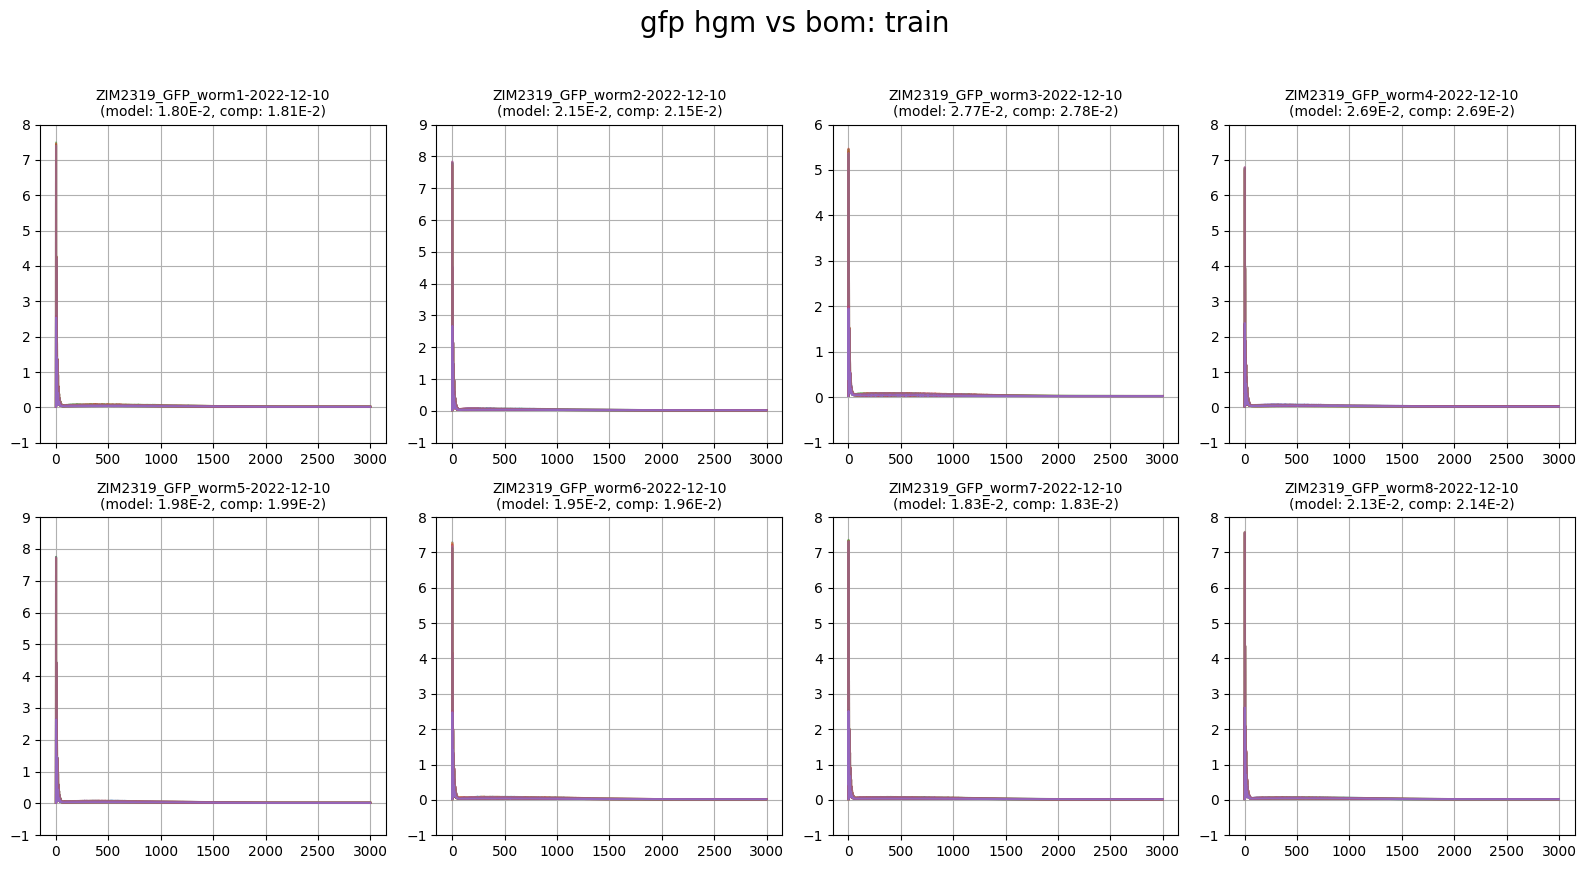

In [31]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: train',
								  filenames_gfp,
								  hgms_losses_train_gfp, boms_losses_train_gfp,
								  ylimits=None)

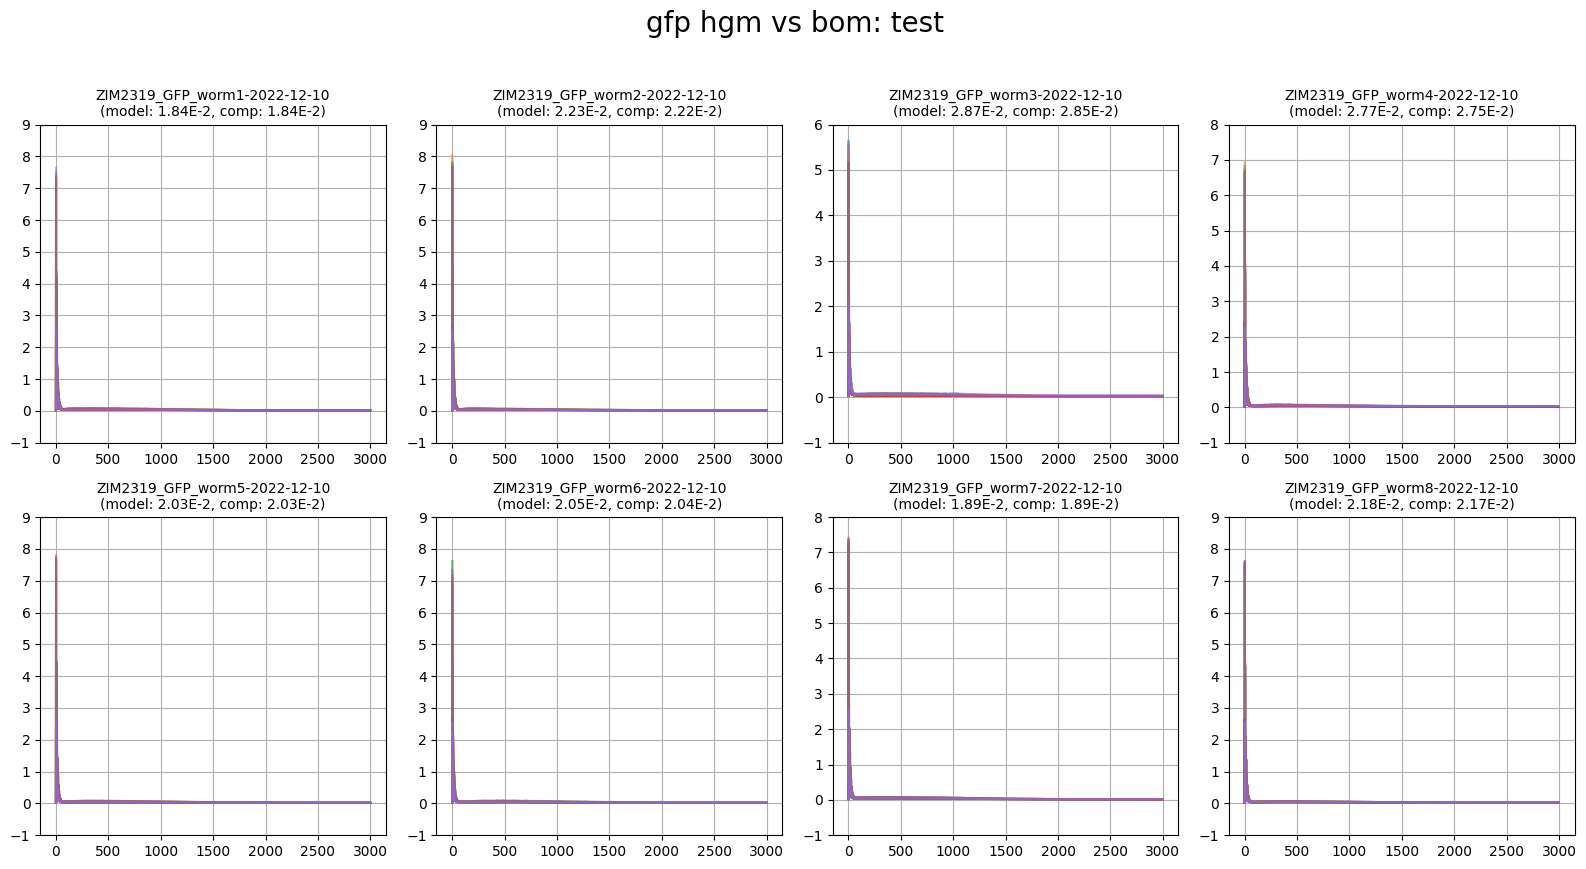

In [32]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: test',
								  filenames_gfp,
								  hgms_losses_gfp, boms_losses_gfp,
								  ylimits=None)

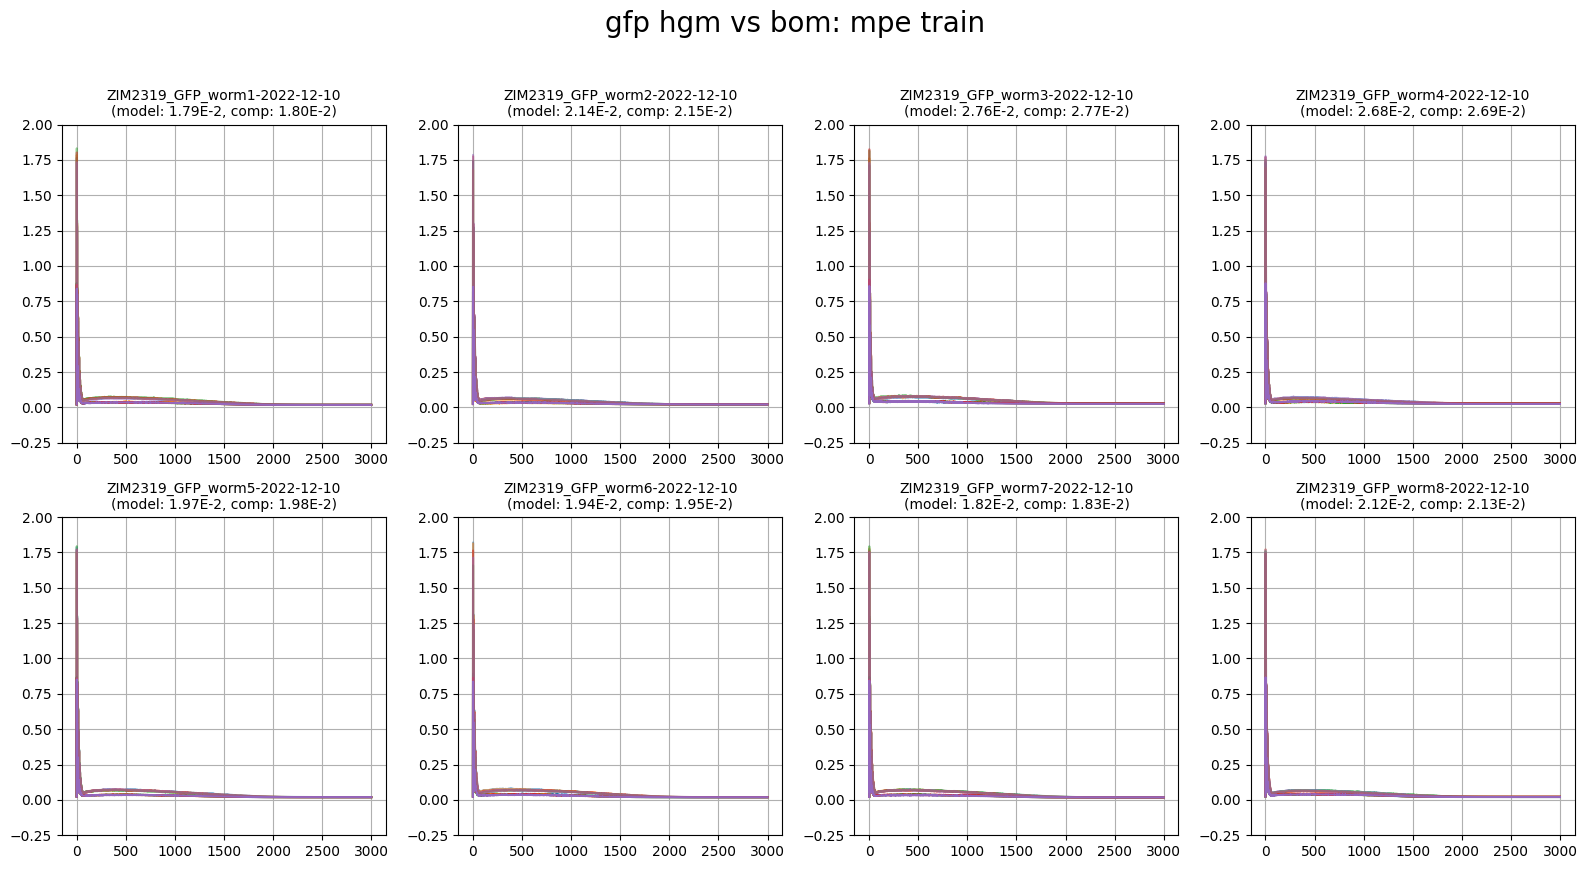

In [33]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe train',
								  filenames_gfp,
								  hgms_mpe_losses_train_gfp, boms_mpe_losses_train_gfp,
								  ylimits=None)

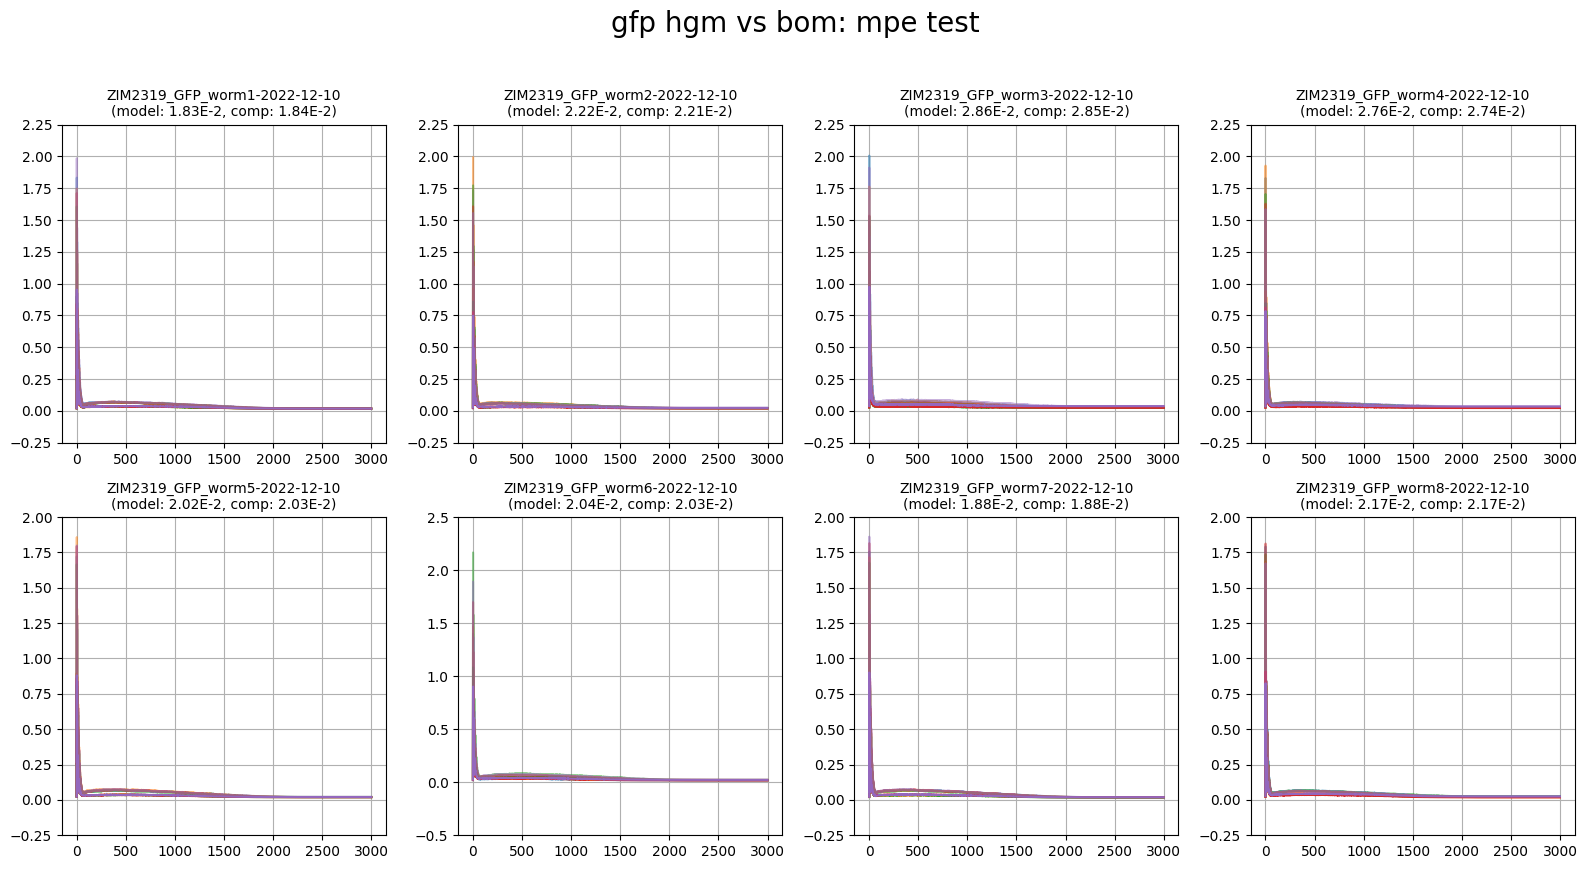

In [34]:
if gfp:
	plot_utils.plot_losses_splits('gfp hgm vs bom: mpe test',
								  filenames_gfp,
								  hgms_mpe_losses_gfp, boms_mpe_losses_gfp,
								  ylimits=None)